In [49]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler ,MinMaxScaler
from sklearn.cluster import KMeans 
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import warnings 
warnings.filterwarnings('ignore')

In [3]:
plt.style.use('seaborn-v0_8-whitegrid') 
sns.set_palette("husl") 
print("="*80) 
print("K-MEANS CLUSTERING: MALL CUSTOMER SEGMENTATION") 
print("="*80) 

K-MEANS CLUSTERING: MALL CUSTOMER SEGMENTATION


In [4]:

df = pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\Mall_Customers.csv") 
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [6]:
print("\n First 5 rows:") 
print(df.head()) 
print("\n Dataset Info:") 
print(df.info()) 
print("\n Statistical Summary:") 
print(df.describe()) 


 First 5 rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

 Statistical Summa

In [7]:
df.isnull().sum()


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64



 STEP 2: Exploratory Data Analysis
--------------------------------------------------


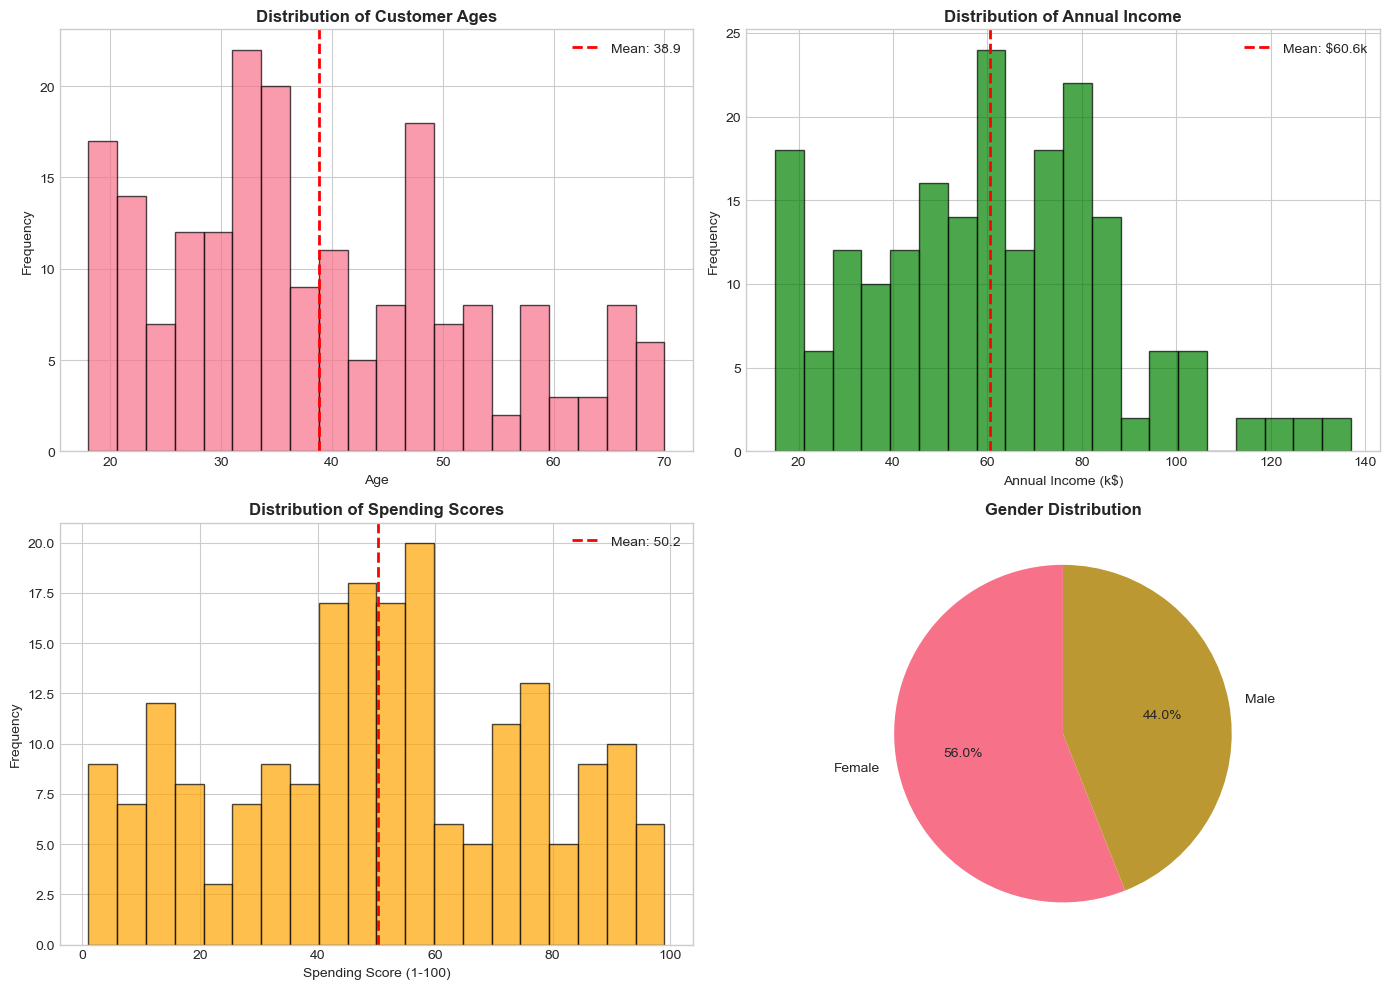

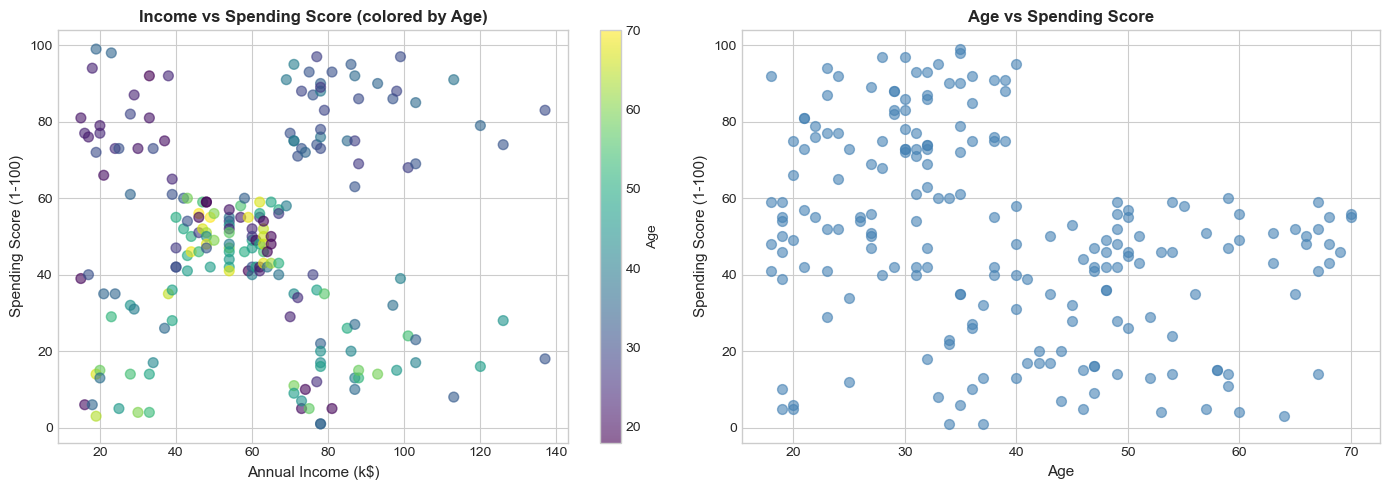

In [20]:
print("\n\n STEP 2: Exploratory Data Analysis") 
print("-"*50) 
 
# Create figure for EDA 
fig, axes = plt.subplots(2, 2, figsize=(14, 10)) 
 
# Distribution of Age 
axes[0, 0].hist(df['Age'], bins=20, edgecolor='black', alpha=0.7) 
axes[0, 0].set_xlabel('Age') 
axes[0, 0].set_ylabel('Frequency') 
axes[0, 0].set_title('Distribution of Customer Ages', fontsize=12, 
fontweight='bold') 
axes[0, 0].axvline(df['Age'].mean(), color='red', linestyle='dashed', 
linewidth=2, label=f"Mean: {df['Age'].mean():.1f}") 
axes[0, 0].legend() 
 
# Distribution of Annual Income 
axes[0, 1].hist(df['Annual Income (k$)'], bins=20, edgecolor='black', 
alpha=0.7, color='green') 
axes[0, 1].set_xlabel('Annual Income (k$)') 
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Distribution of Annual Income', fontsize=12, 
fontweight='bold') 
axes[0, 1].axvline(df['Annual Income (k$)'].mean(), color='red', 
linestyle='dashed', linewidth=2, label=f"Mean: ${df['Annual Income (k$)'].mean():.1f}k") 
axes[0, 1].legend()
# Distribution of Spending Score 
axes[1, 0].hist(df['Spending Score (1-100)'], bins=20, edgecolor='black', 
alpha=0.7, color='orange') 
axes[1, 0].set_xlabel('Spending Score (1-100)') 
axes[1, 0].set_ylabel('Frequency') 
axes[1, 0].set_title('Distribution of Spending Scores', fontsize=12, 
fontweight='bold') 
axes[1, 0].axvline(df['Spending Score (1-100)'].mean(), color='red', 
linestyle='dashed', linewidth=2, label=f"Mean: {df['Spending Score (1-100)'].mean():.1f}") 
axes[1, 0].legend() 
# Gender distribution (if available) 
if 'Gender' in df.columns: 
   gender_counts = df['Gender'].value_counts() 
   axes[1, 1].pie(gender_counts.values, labels=gender_counts.index, 
   autopct='%1.1f%%', startangle=90) 
   axes[1, 1].set_title('Gender Distribution', fontsize=12,fontweight='bold') 
else: 
   axes[1, 1].scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], alpha=0.6) 
   axes[1, 1].set_xlabel('Annual Income (k$)') 
   axes[1, 1].set_ylabel('Spending Score') 
   axes[1, 1].set_title('Income vs Spending Score', fontsize=12, 
fontweight='bold') 
plt.tight_layout() 
plt.savefig('eda_visualizations.png', dpi=300, bbox_inches='tight') 
plt.show() 
# Relationship between features 
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) 
# Income vs Spending Score (key relationship for clustering) 
scatter = axes[0].scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'],  
c=df['Age'], cmap='viridis', alpha=0.6, s=50) 
axes[0].set_xlabel('Annual Income (k$)', fontsize=11) 
axes[0].set_ylabel('Spending Score (1-100)', fontsize=11) 
axes[0].set_title('Income vs Spending Score (colored by Age)', fontsize=12, 
fontweight='bold') 
plt.colorbar(scatter, ax=axes[0], label='Age') 
# Age vs Spending Score 
axes[1].scatter(df['Age'], df['Spending Score (1-100)'], alpha=0.6, 
c='steelblue', s=50) 
axes[1].set_xlabel('Age', fontsize=11) 
axes[1].set_ylabel('Spending Score (1-100)', fontsize=11) 
axes[1].set_title('Age vs Spending Score', fontsize=12, fontweight='bold') 
plt.tight_layout() 
plt.savefig('feature_relationships.png', dpi=300, bbox_inches='tight') 
plt.show() 

<Figure size 640x480 with 0 Axes>

In [13]:
df


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [25]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values 
print(f" Selected features: {features}") 
print(f" Feature matrix shape: {X.shape}") 
# Standardize the features (crucial for k-means) 
scaler = StandardScaler() 
X_scaled = scaler.fit_transform(X) 
print(" Features standardized (mean=0, std=1)") 
# Display sample of scaled data 
print("\n Sample of scaled features (first 10 rows):") 
print(pd.DataFrame(X[:10], columns=['Income', 'Spending'])) 

 Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']
 Feature matrix shape: (200, 2)
 Features standardized (mean=0, std=1)

 Sample of scaled features (first 10 rows):
   Income  Spending
0      15        39
1      15        81
2      16         6
3      16        77
4      17        40
5      17        76
6      18         6
7      18        94
8      19         3
9      19        72




 STEP 4: Finding Optimal Number of Clusters
--------------------------------------------------


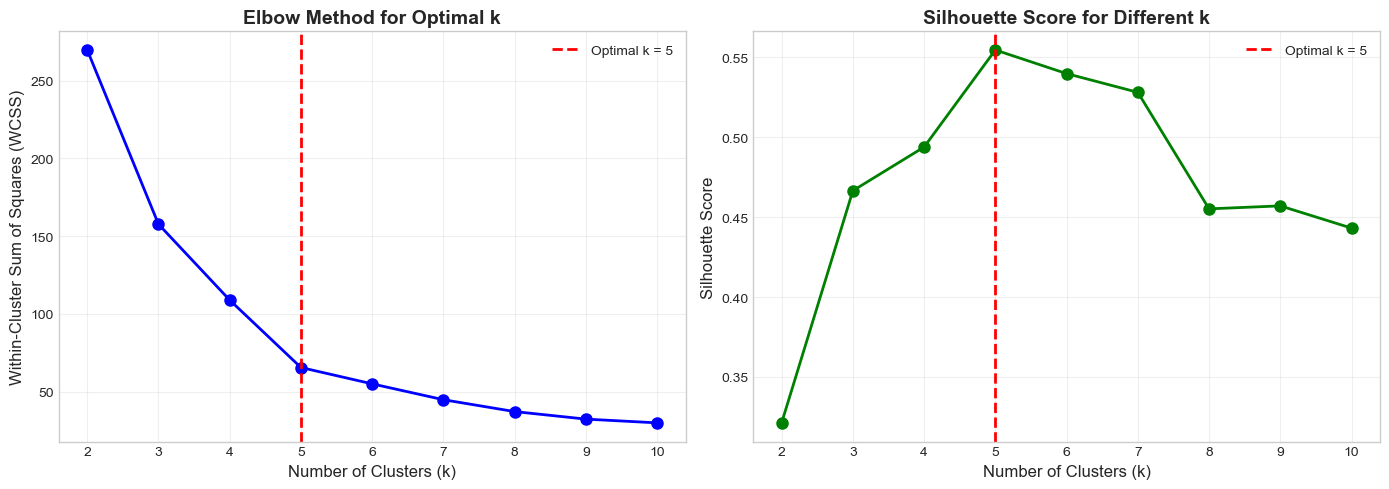


 Optimal number of clusters determined: k = 5
   (Based on elbow point at k=5 and high silhouette score)0    0.554657
dtype: float64


In [54]:
print("\n\n STEP 4: Finding Optimal Number of Clusters") 
print("-"*50) 
# Calculate WCSS (Within-Cluster Sum of Squares) for different k values 
wcss = [] 
silhouette_scores = [] 
k_range = range(2, 11) 
for k in k_range: 
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10) 
    kmeans.fit(X_scaled) 
    wcss.append(kmeans.inertia_) 
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_)) 
# Create elbow method visualization 
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) 
# Elbow Method Plot
axes[0].plot(k_range, wcss, 'bo-', linewidth=2, markersize=8) 
axes[0].axvline(x=5, color='red', linestyle='--', linewidth=2, 
label='Optimal k = 5') 
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12) 
axes[0].set_ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12) 
axes[0].set_title('Elbow Method for Optimal k', fontsize=14, fontweight='bold') 
axes[0].grid(True, alpha=0.3) 
axes[0].legend() 
# Silhouette Score Plot 
axes[1].plot(k_range, silhouette_scores, 'go-', linewidth=2, markersize=8) 
axes[1].axvline(x=5, color='red', linestyle='--', linewidth=2, 
label='Optimal k = 5') 
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12) 
axes[1].set_ylabel('Silhouette Score', fontsize=12) 
axes[1].set_title('Silhouette Score for Different k', fontsize=14, 
fontweight='bold') 
axes[1].grid(True, alpha=0.3) 
axes[1].legend() 
plt.tight_layout() 
plt.savefig('optimal_k_determination.png', dpi=300, bbox_inches='tight') 
plt.show() 
# Determine optimal k (elbow at k=5) 
sil=pd.DataFrame(silhouette_scores)
optimal_k = 5 
print(f"\n Optimal number of clusters determined: k = {optimal_k}") 
print(f"   (Based on elbow point at k=5 and high silhouette score){sil.max()}")


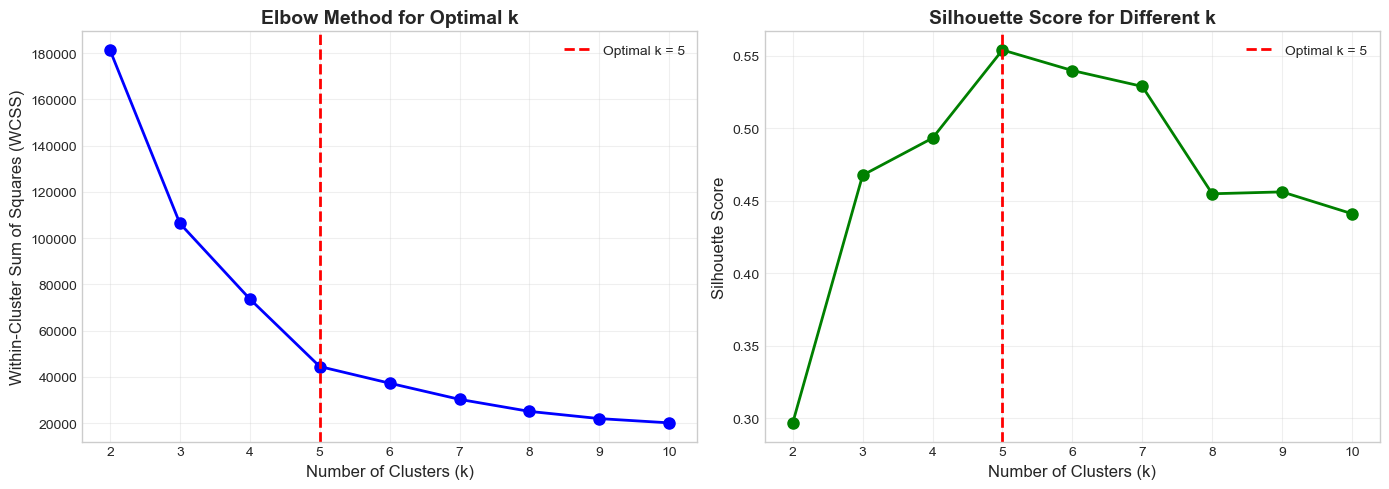


 Optimal number of clusters determined: k = 5
   (Based on elbow point at k=5 and high silhouette score)0    0.553932
dtype: float64


In [55]:
wcss = [] 
silhouette_scores = [] 
k_range = range(2, 11) 
for k in k_range: 
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10) 
    kmeans.fit(X) 
    wcss.append(kmeans.inertia_) 
    silhouette_scores.append(silhouette_score(X, kmeans.labels_)) 
# Create elbow method visualization 
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) 
# Elbow Method Plot
axes[0].plot(k_range, wcss, 'bo-', linewidth=2, markersize=8) 
axes[0].axvline(x=5, color='red', linestyle='--', linewidth=2, 
label='Optimal k = 5') 
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12) 
axes[0].set_ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12) 
axes[0].set_title('Elbow Method for Optimal k', fontsize=14, 
fontweight='bold') 
axes[0].grid(True, alpha=0.3) 
axes[0].legend() 
# Silhouette Score Plot 
axes[1].plot(k_range, silhouette_scores, 'go-', linewidth=2, markersize=8) 
axes[1].axvline(x=5, color='red', linestyle='--', linewidth=2, 
label='Optimal k = 5') 
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12) 
axes[1].set_ylabel('Silhouette Score', fontsize=12) 
axes[1].set_title('Silhouette Score for Different k', fontsize=14, 
fontweight='bold') 
axes[1].grid(True, alpha=0.3) 
axes[1].legend() 
plt.tight_layout() 
plt.savefig('optimal_k_determination.png', dpi=300, bbox_inches='tight') 
plt.show() 
# Determine optimal k (elbow at k=5) 
optimal_k = 5 
sil=pd.DataFrame(silhouette_scores)
print(f"\n Optimal number of clusters determined: k = {optimal_k}") 
print(f"   (Based on elbow point at k=5 and high silhouette score){sil.max()}")

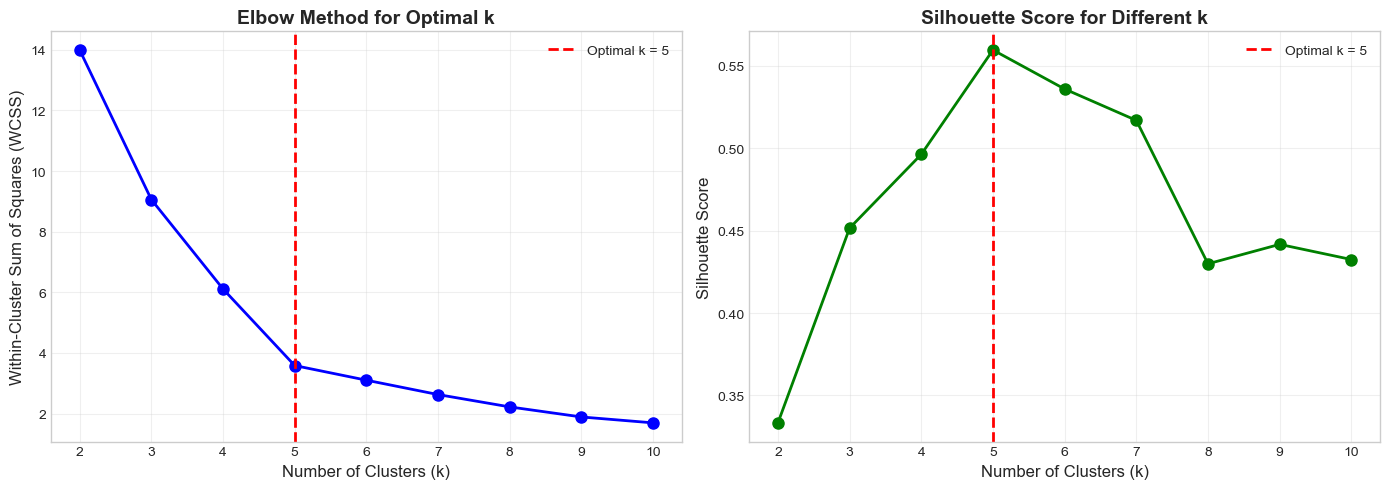


 Optimal number of clusters determined: k = 5
   (Based on elbow point at k=5 and high silhouette score)0    0.559485
dtype: float64


In [52]:
scale=MinMaxScaler()
X_scale=scale.fit_transform(X)
wcss = [] 
silhouette_scores = [] 
k_range = range(2, 11) 
for k in k_range: 
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10) 
    kmeans.fit(X_scale) 
    wcss.append(kmeans.inertia_) 
    silhouette_scores.append(silhouette_score(X_scale, kmeans.labels_)) 
# Create elbow method visualization 
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) 
# Elbow Method Plot
axes[0].plot(k_range, wcss, 'bo-', linewidth=2, markersize=8) 
axes[0].axvline(x=5, color='red', linestyle='--', linewidth=2, 
label='Optimal k = 5') 
axes[0].set_xlabel('Number of Clusters (k)', fontsize=12) 
axes[0].set_ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12) 
axes[0].set_title('Elbow Method for Optimal k', fontsize=14, 
fontweight='bold') 
axes[0].grid(True, alpha=0.3) 
axes[0].legend() 
# Silhouette Score Plot 
axes[1].plot(k_range, silhouette_scores, 'go-', linewidth=2, markersize=8) 
axes[1].axvline(x=5, color='red', linestyle='--', linewidth=2, 
label='Optimal k = 5') 
axes[1].set_xlabel('Number of Clusters (k)', fontsize=12) 
axes[1].set_ylabel('Silhouette Score', fontsize=12) 
axes[1].set_title('Silhouette Score for Different k', fontsize=14, 
fontweight='bold') 
axes[1].grid(True, alpha=0.3) 
axes[1].legend() 
plt.tight_layout() 
plt.savefig('optimal_k_determination.png', dpi=300, bbox_inches='tight') 
plt.show() 
# Determine optimal k (elbow at k=5) 
optimal_k = 5 
sil=pd.DataFrame(silhouette_scores)

print(f"\n Optimal number of clusters determined: k = {optimal_k}") 
print(f"   (Based on elbow point at k=5 and high silhouette score){sil.max()}")

In [28]:
print("\n\n STEP 5: Applying K-Means Clustering") 
print("-"*50) 
# Apply K-Means with optimal k 
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, 
n_init=10) 
y_kmeans = kmeans.fit_predict(X_scaled) 
# Add cluster labels to original dataframe 
df['Cluster'] = y_kmeans 
# Get cluster centers (in original scale for interpretation) 
centers_original = scaler.inverse_transform(kmeans.cluster_centers_) 
print(" K-Means clustering completed!") 
print(f"\n Cluster Distribution:") 
cluster_counts = df['Cluster'].value_counts().sort_index() 
for i in range(optimal_k): 
    print(f"   Cluster {i}: {cluster_counts[i]} customers ({cluster_counts[i]/len(df)*100:.1f}%)")



 STEP 5: Applying K-Means Clustering
--------------------------------------------------
 K-Means clustering completed!

 Cluster Distribution:
   Cluster 0: 81 customers (40.5%)
   Cluster 1: 39 customers (19.5%)
   Cluster 2: 22 customers (11.0%)
   Cluster 3: 35 customers (17.5%)
   Cluster 4: 23 customers (11.5%)




 STEP 6: Cluster Visualization
--------------------------------------------------


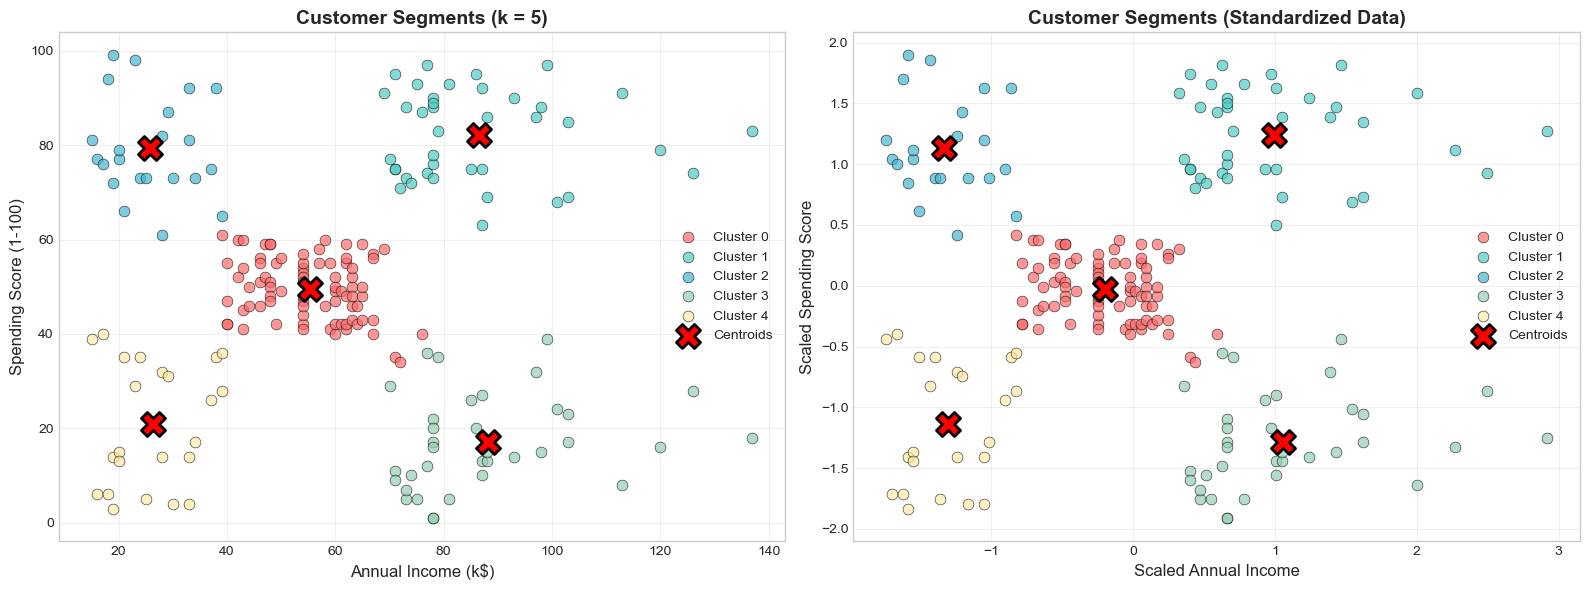

In [33]:
print("\n\n STEP 6: Cluster Visualization") 
print("-"*50) 
# Create color map for clusters 
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7'] 
# Main cluster visualization 
fig, axes = plt.subplots(1, 2, figsize=(16, 6)) 
# Scatter plot of clusters (Original Scale) 
for i in range(optimal_k): 
    cluster_data = df[df['Cluster'] == i] 
    axes[0].scatter(cluster_data['Annual Income (k$)'],  
    cluster_data['Spending Score (1-100)'], c=colors[i], label=f'Cluster {i}', alpha=0.7, s=60, edgecolors='black', linewidth=0.5) 
# Plot centroids 
axes[0].scatter(centers_original[:, 0], centers_original[:, 1],  
c='red', marker='X', s=300, edgecolors='black', 
linewidth=2,  
label='Centroids') 
axes[0].set_xlabel('Annual Income (k$)', fontsize=12) 
axes[0].set_ylabel('Spending Score (1-100)', fontsize=12)
axes[0].set_title(f'Customer Segments (k = {optimal_k})', fontsize=14, 
fontweight='bold') 
axes[0].legend(loc='best', fontsize=10) 
axes[0].grid(True, alpha=0.3) 
# Scatter plot of clusters (Scaled data) 
for i in range(optimal_k): 
    cluster_data_scaled = X_scaled[y_kmeans == i] 
    axes[1].scatter(cluster_data_scaled[:, 0], cluster_data_scaled[:, 1], 
    c=colors[i], label=f'Cluster {i}', alpha=0.7, s=60, edgecolors='black', linewidth=0.5) 
# Plot centroids (scaled) 
axes[1].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:,1], 
c='red', marker='X', s=300, edgecolors='black', 
linewidth=2,  
label='Centroids') 
axes[1].set_xlabel('Scaled Annual Income', fontsize=12) 
axes[1].set_ylabel('Scaled Spending Score', fontsize=12) 
axes[1].set_title('Customer Segments (Standardized Data)', fontsize=14, 
fontweight='bold') 
axes[1].legend(loc='best', fontsize=10) 
axes[1].grid(True, alpha=0.3) 
plt.tight_layout() 
plt.savefig('cluster_visualization.png', dpi=300, bbox_inches='tight') 
plt.show()